# 5. Serving and latency

The model scored one transaction at a time by a service that keeps a time-sorted neighbour index. Numbers come from one machine replaying historical data; they are not a production claim, and the 100 ms budget is an illustrative assumption.

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
import json
lat = load_results('latency.csv')
meta = json.loads((out_dir() / 'latency_meta.json').read_text())
print('FIXTURE RESULTS - not findings' if meta['fixture'] else 'real data')
print('hardware:', meta['hardware'])
print('parity with the offline scores:', meta['parity'])

real data
hardware: {'platform': 'Windows-11-10.0.26300-SP0', 'processor': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'cpu_count': 16, 'python': '3.14.7', 'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 3070 Ti Laptop GPU'}
parity with the offline scores: {'checked': True, 'max_abs_diff': 0.0, 'n_rows': 200, 'reason': ''}


In [2]:
cols = ['model', 'device', 'mode', 'batch_size', 'concurrency', 'p50_ms', 'p95_ms', 'p99_ms', 'throughput_rps', 'p99_within_budget']
aggregate_latency(lat)[[c for c in cols if c not in ('p99_within_budget',)] + ['p50_min_ms', 'p50_max_ms', 'repeats']].round(2)

,model,device,mode,batch_size,concurrency,p50_ms,p95_ms,p99_ms,throughput_rps,p50_min_ms,p50_max_ms,repeats
0,gnn,cpu,inprocess,1,1,19.04,21.13,22.86,53.40,19.00,19.19,3
1,gnn,cpu,inprocess,8,1,25.80,28.77,30.57,313.89,25.76,26.16,3
2,gnn,cpu,inprocess,32,1,44.22,51.66,60.81,715.58,43.80,45.25,3
3,gnn,cpu,inprocess,128,1,135.95,151.73,153.80,935.98,134.02,143.27,3
4,gnn,cuda,inprocess,1,1,25.88,33.45,37.63,37.59,25.45,26.06,3
5,gnn,cuda,inprocess,8,1,32.73,39.82,42.72,240.65,32.23,32.80,3
6,gnn,cuda,inprocess,32,1,46.97,55.39,65.24,668.04,46.77,47.28,3
7,gnn,cuda,inprocess,128,1,119.21,133.01,136.11,1073.71,119.00,119.30,3
8,gnn,cpu,http,1,1,21.00,24.15,25.55,46.93,20.94,21.28,3
9,gnn,cpu,http,32,1,55.34,61.86,63.83,566.93,55.16,57.70,3


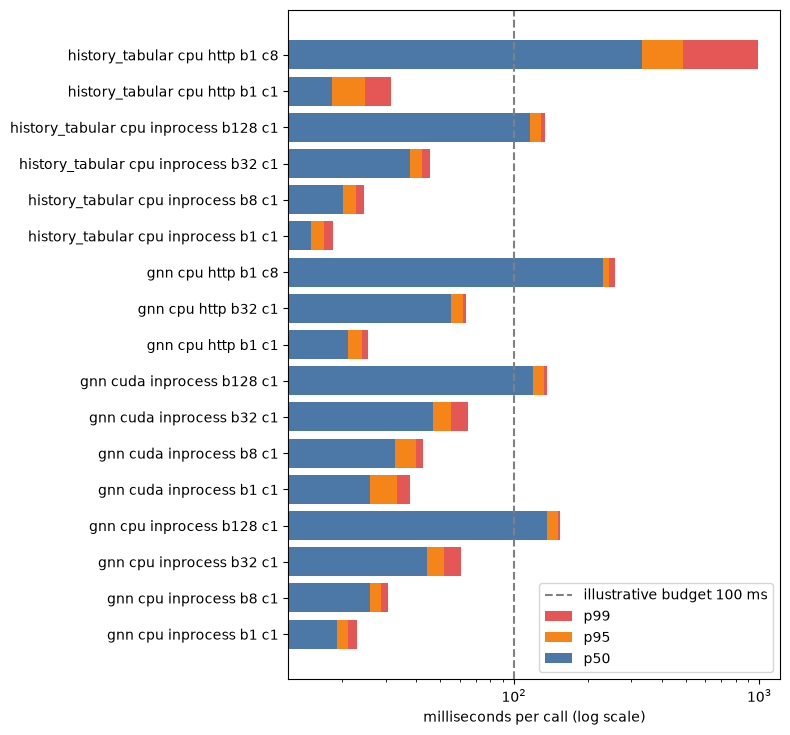

In [3]:
plot_latency(lat, meta['budget_ms']);

## Where the time goes (batch size 1)

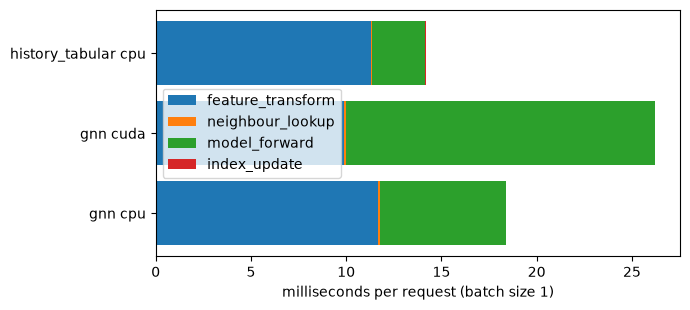

In [4]:
plot_breakdown(lat);

## Stock sampler versus the custom index

The `stock_neighbor_loader` row is the cost of sampling the neighbourhood alone with PyG's loader built per request; compare it with the `neighbour_lookup` share above.

In [5]:
aggregate_latency(lat[lat['mode'] == 'lookup_only'])[['model', 'p50_ms', 'p95_ms', 'p99_ms', 'repeats']].round(2)

,model,p50_ms,p95_ms,p99_ms,repeats
0,stock_neighbor_loader,443.76,542.7,635.98,3


Index size and the concurrency caveat: the metadata printed above lists the indexed transactions and the serialised index size. Scoring is serialised by one lock, so extra clients do not add throughput; the multi-client row shows the queueing cost.